# ACL Tear Detection on MRNet — Robust GPU-Safe Version

**Paper:** Deep Learning-Assisted Automatic Diagnosis of ACL Tear in Knee MRI  
**Journal:** Tomography (MDPI), 2024 | **DOI:** 10.3390/tomography10080094


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Step 1: Install & Download MRNet Dataset

In [ ]:
import os
from google.colab import userdata

os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY']      = userdata.get('KAGGLE_KEY')

!pip install -q kaggle
!kaggle datasets download -d cjinny/mrnet-v1 -p /content/ --unzip
!ls /content/MRNet-v1.0

Dataset URL: https://www.kaggle.com/datasets/cjinny/mrnet-v1
License(s): unknown
100% 5.68G/5.68G [05:12<00:00, 19.5MB/s]

train		    train-acl.csv	valid		    valid-acl.csv
train-abnormal.csv  train-meniscus.csv	valid-abnormal.csv  valid-meniscus.csv


In [ ]:
!pip install -q timm scikit-learn matplotlib pandas

## Step 2: Config

In [ ]:
import os, time, copy, random, warnings, gc, json, pickle
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F, torchvision, timm
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, roc_curve, confusion_matrix)
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

MODEL_TO_RUN = None

CFG = dict(
    data_root   = '/content/MRNet-v1.0',
    views       = ['axial', 'coronal', 'sagittal'],

    max_train   = None,
    n_slices    = 12,
    epochs      = 25,

    patience        = 5,

    batch_size      = 2,
    num_workers     = 0,
    pin_memory      = False,
    lr_head         = 1e-4,
    lr_backbone     = 1e-5,
    weight_decay    = 0.01,
    focal_gamma     = 2.0,
    label_smooth    = 0.05,
    n_tta           = 3,
    mixup_alpha     = 0.2,
    seed            = 42,
    pretrained      = True,
    out_dir         = '/content/drive/MyDrive/ACL_outputs',
    ckpt_dir        = '/content/drive/MyDrive/ACL_outputs/ckpt',
    results_file    = '/content/drive/MyDrive/ACL_outputs/partial_results.pkl'
)

PAPER = dict(
    title   = 'Deep Learning-Assisted Automatic Diagnosis of Anterior Cruciate Ligament Tear in Knee Magnetic Resonance Images',
    doi     = '10.3390/tomography10080094',
    journal = 'Tomography (MDPI), 2024'
)

VIEWS, K = CFG['views'], CFG['n_slices']
os.makedirs(CFG['out_dir'],  exist_ok=True)
os.makedirs(CFG['ckpt_dir'], exist_ok=True)
DEV     = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEV.type == 'cuda'
SYNTH   = not os.path.isdir(CFG['data_root'])

def seed_all(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def free_gpu():
    """Aggressively release GPU memory."""
    gc.collect()
    torch.cuda.empty_cache()
    if USE_AMP:
        torch.cuda.synchronize()

def gpu_used_mb():
    return torch.cuda.memory_allocated() / 2**20 if USE_AMP else 0.

seed_all(CFG['seed'])
print(f'Device: {DEV} | AMP: {USE_AMP} | Data: {"SYNTHETIC" if SYNTH else "MRNet"}')
print(f'Config: {CFG["max_train"] or 1130} exams | {K} slices | {CFG["epochs"]} epochs')
print(f'GPU memory at start: {gpu_used_mb():.0f} MB')
if MODEL_TO_RUN:
    print(f'► Single-model mode: will only train {MODEL_TO_RUN}')

Device: cuda | AMP: True | Data: MRNet
Config: 1130 exams | 12 slices | 25 epochs
GPU memory at start: 16 MB


## Step 3: Data Loading

In [ ]:
def pick_slices(n):
    return np.linspace(int(.2*(n-1)), int(.8*(n-1)), K).round().astype(int)

def read_view(paths):
    out = []
    for j, p in enumerate(paths):
        a = np.load(p)
        assert a.ndim == 3 and a.shape[1:] == (256,256) and np.isfinite(a).all(), p
        out.append(a[pick_slices(len(a))].astype(np.uint8))
        if j % 300 == 0: print(f'  loaded {j}/{len(paths)}')
    return out

def synth_vols(ys, seed):
    rng = np.random.default_rng(seed)
    yy, xx = np.mgrid[:256, :256]
    out = []
    for y in ys:
        v  = rng.normal(0.3, 0.1, (K, 256, 256))
        cx, cy = rng.integers(100, 156, 2)
        v += (0.5 if y else .15) * np.exp(-(((xx-cx)**2+(yy-cy)**2)/(2*(20 if y else 12)**2)))
        out.append((v.clip(0,1)*255).astype(np.uint8))
    return out

def build_data():
    r = CFG['data_root']
    if SYNTH:
        g = np.random.default_rng(0)
        y_trf = (g.random(120) < .4).astype(int)
        y_te  = (g.random(40)  < .4).astype(int)
    else:
        rd = lambda s: pd.read_csv(f'{r}/{s}-acl.csv', header=None, names=['id','y'])
        dtr, dte = rd('train'), rd('valid')
        if CFG['max_train'] and len(dtr) > CFG['max_train']:
            dtr, _ = train_test_split(dtr, train_size=CFG['max_train'],
                                      stratify=dtr.y, random_state=CFG['seed'])
            dtr = dtr.reset_index(drop=True)
        y_trf, y_te = dtr.y.values, dte.y.values

    def vols(split, v):
        if SYNTH:
            return synth_vols(y_trf if split=='train' else y_te,
                              100*VIEWS.index(v)+(split!='train'))
        ids = (dtr if split=='train' else dte).id.values
        return read_view([f'{r}/{split}/{v}/{i:04d}.npy' for i in ids])

    itr, iva = train_test_split(np.arange(len(y_trf)), test_size=.2,
                                stratify=y_trf, random_state=CFG['seed'])
    D = {}
    for v in VIEWS:
        print('loading', v)
        a, t = vols('train', v), vols('valid', v)
        sub = np.stack([a[i] for i in itr[:64]]).astype(np.float32)
        D[v] = dict(
            train = ([a[i] for i in itr], y_trf[itr]),
            val   = ([a[i] for i in iva], y_trf[iva]),
            test  = (t, y_te),
            mean  = float(sub.mean()),
            std   = float(sub.std())
        )
        del a, t, sub; gc.collect()
    return D

DATA = build_data()
ytr  = DATA[VIEWS[0]]['train'][1]
ALPHA = 1 - ytr.mean()
print({s: (len(DATA[VIEWS[0]][s][1]),
           f'{DATA[VIEWS[0]][s][1].mean():.2f} pos')
       for s in ['train','val','test']}, f'alpha={ALPHA:.2f}')

loading axial
  loaded 0/1130
  loaded 300/1130
  loaded 600/1130
  loaded 900/1130
  loaded 0/120
loading coronal
  loaded 0/1130
  loaded 300/1130
  loaded 600/1130
  loaded 900/1130
  loaded 0/120
loading sagittal
  loaded 0/1130
  loaded 300/1130
  loaded 600/1130
  loaded 900/1130
  loaded 0/120
{'train': (904, '0.18 pos'), 'val': (226, '0.19 pos'), 'test': (120, '0.45 pos')} alpha=0.82


## Step 4: Dataset & Augmentation

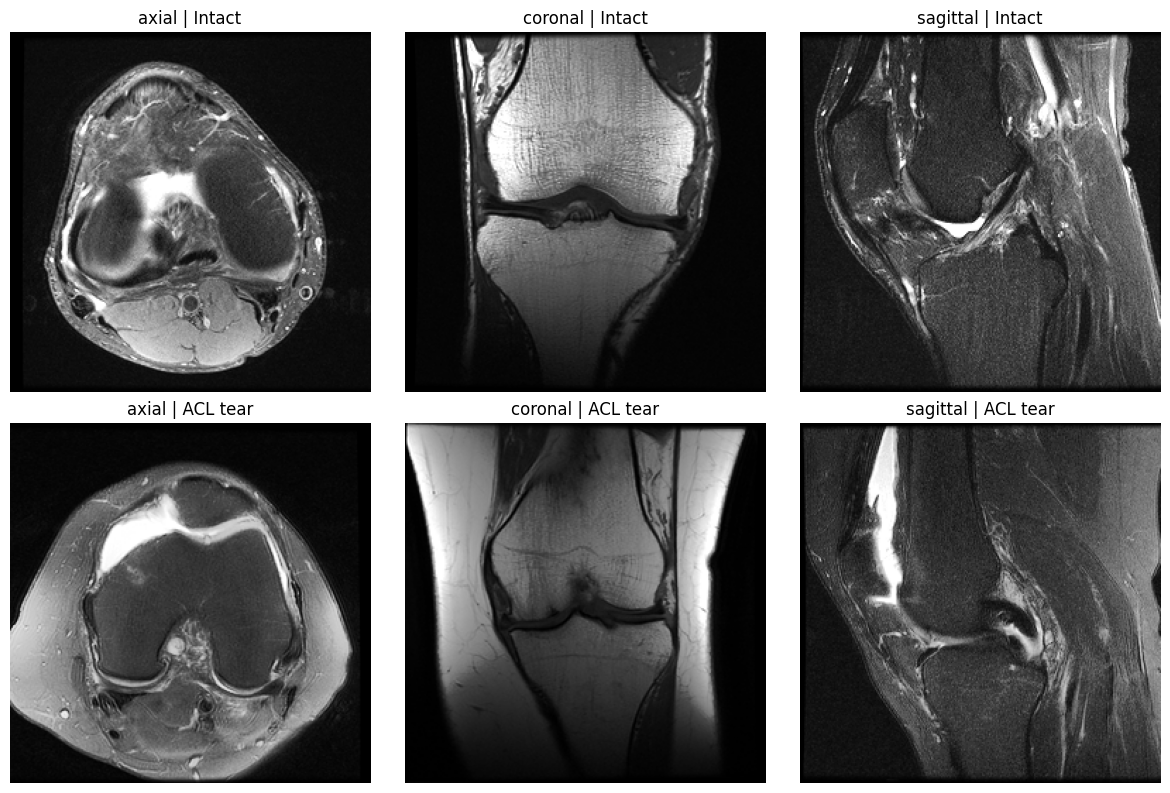

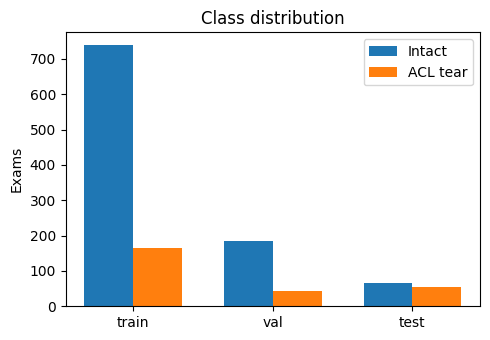

In [ ]:
class KneeMRI(Dataset):
    def __init__(self, split, view, train):
        self.a, self.y = DATA[view][split]
        self.train = train
        self.m, self.s = DATA[view]['mean'], DATA[view]['std']

    def __len__(self): return len(self.y)

    def __getitem__(self, i):
        x = torch.from_numpy(self.a[i]).float()
        if self.train:
            if random.random() < .5:
                x = TF.hflip(x)
            x = TF.rotate(x, random.uniform(-10, 10))
            t, l = random.randint(0,32), random.randint(0,32)
            x = x[:, t:t+224, l:l+224]
            if random.random() < 0.4:
                x = x.clamp(0) ** random.uniform(0.8, 1.2)
            if random.random() < 0.3:
                x = x + torch.randn_like(x) * (x.std() * 0.05)
        else:
            x = TF.center_crop(x, [224, 224])
        x = ((x - self.m) / (self.s + 1e-8)).unsqueeze(1).repeat(1, 3, 1, 1)
        return x, torch.tensor(float(self.y[i]))


def mixup_batch(x, y, alpha=0.2):
    if alpha <= 0 or not torch.is_grad_enabled(): return x, y
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(x.size(0), device=x.device)
    return lam*x + (1-lam)*x[idx], lam*y + (1-lam)*y[idx]


def loaders(view):
    mk = lambda s, tr: DataLoader(
        KneeMRI(s, view, tr),
        batch_size  = CFG['batch_size'],
        shuffle     = tr,
        num_workers = CFG['num_workers'],
        pin_memory  = CFG['pin_memory'],
        drop_last   = tr
    )
    return mk('train',True), mk('val',False), mk('test',False)


# Quick dataset visualisation
fig, ax = plt.subplots(2, len(VIEWS), figsize=(4*len(VIEWS), 8), squeeze=False)
for j, v in enumerate(VIEWS):
    a, y = DATA[v]['train']
    for i, c in enumerate([0,1]):
        ax[i,j].imshow(a[int(np.where(y==c)[0][0])][K//2], cmap='gray')
        ax[i,j].set_title(f'{v} | {"ACL tear" if c else "Intact"}')
        ax[i,j].axis('off')
plt.tight_layout()
plt.savefig(f"{CFG['out_dir']}/sample_images.png", dpi=100); plt.show()

cnt = {s: np.bincount(DATA[VIEWS[0]][s][1], minlength=2) for s in ['train','val','test']}
fig, ax = plt.subplots(figsize=(5,3.5)); w=.35; xs=np.arange(3)
ax.bar(xs-w/2,[cnt[s][0] for s in cnt],w,label='Intact')
ax.bar(xs+w/2,[cnt[s][1] for s in cnt],w,label='ACL tear')
ax.set_xticks(xs); ax.set_xticklabels(list(cnt))
ax.set(ylabel='Exams',title='Class distribution'); ax.legend()
plt.tight_layout()
plt.savefig(f"{CFG['out_dir']}/class_distribution.png", dpi=100); plt.show()

## Step 5: Models — Gated Attention MIL + Gradient Checkpointing

In [ ]:
from torch.utils.checkpoint import checkpoint as grad_ckpt

# Models that benefit from gradient checkpointing (memory-heavy)
USE_GRAD_CKPT = {'EfficientNetV2-S', 'Swin-T'}


class GatedAttentionMIL(nn.Module):
    """Slice-level MIL with Gated Attention pooling (Ilse et al., 2018)."""
    def __init__(self, bb, d, hidden=128, dropout=0.25, use_grad_ckpt=False):
        super().__init__()
        self.backbone      = bb
        self.use_grad_ckpt = use_grad_ckpt
        self.attn_V = nn.Sequential(nn.Linear(d, hidden), nn.Tanh())
        self.attn_U = nn.Sequential(nn.Linear(d, hidden), nn.Sigmoid())
        self.attn_w = nn.Linear(hidden, 1)
        self.drop   = nn.Dropout(dropout)
        self.head   = nn.Linear(d, 1)

    def _bb_forward(self, x_flat):
        return self.backbone(x_flat)

    def forward(self, x):                      # x: (B, K, 3, H, W)
        B, K_ = x.shape[:2]
        x_flat = x.flatten(0,1)                # (B*K, 3, H, W)
        if self.use_grad_ckpt and self.training:
            feats = grad_ckpt(self._bb_forward, x_flat, use_reentrant=False)
        else:
            feats = self.backbone(x_flat)
        feats = feats.view(B, K_, -1)
        feats = self.drop(feats)
        a = self.attn_w(self.attn_V(feats) * self.attn_U(feats))
        a = torch.softmax(a, dim=1)
        pooled = (a * feats).sum(1)
        return self.head(pooled).squeeze(1)


def alexnet_bb():
    try:
        m = torchvision.models.alexnet(weights='IMAGENET1K_V1' if CFG['pretrained'] else None)
    except Exception as e:
        print('AlexNet weights error:', e); m = torchvision.models.alexnet(weights=None)
    return nn.Sequential(m.features, nn.AdaptiveAvgPool2d(1), nn.Flatten()), 256

def resnet50_bb():
    try:
        m = torchvision.models.resnet50(
            weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2 if CFG['pretrained'] else None)
    except Exception as e:
        print('ResNet-50 weights error:', e); m = torchvision.models.resnet50(weights=None)
    d = m.fc.in_features; m.fc = nn.Identity()
    return m, d

def timm_bb(name):
    try:
        m = timm.create_model(name, pretrained=CFG['pretrained'], num_classes=0)
    except Exception as e:
        print(f'{name} weights error ({e}); random init')
        m = timm.create_model(name, pretrained=False, num_classes=0)
    return m, m.num_features


BUILDERS = {
    'MRNet-AlexNet (Baseline)': alexnet_bb,
    'ResNet-50':                 resnet50_bb,
    'EfficientNetV2-S':          lambda: timm_bb('tf_efficientnetv2_s'),
    'ConvNeXt-Tiny':             lambda: timm_bb('convnext_tiny'),
    'Swin-T':                    lambda: timm_bb('swin_tiny_patch4_window7_224'),
}
BASELINE, MODERN = 'MRNet-AlexNet (Baseline)', 'ConvNeXt-Tiny'

if MODEL_TO_RUN:
    assert MODEL_TO_RUN in BUILDERS, f'Unknown model: {MODEL_TO_RUN}'
    BUILDERS_RUN = {MODEL_TO_RUN: BUILDERS[MODEL_TO_RUN]}
else:
    BUILDERS_RUN = BUILDERS

print('Models to run:', list(BUILDERS_RUN.keys()))

Models to run: ['MRNet-AlexNet (Baseline)', 'ResNet-50', 'EfficientNetV2-S', 'ConvNeXt-Tiny', 'Swin-T']


## Step 6: Loss — Weighted BCE + Focal + Label Smoothing

In [ ]:
def paper_loss(logit, y):
    ls = CFG['label_smooth']
    y_smooth = y * (1 - ls) + ls * 0.5
    bce  = F.binary_cross_entropy_with_logits(logit, y_smooth, reduction='none')
    pt   = torch.exp(-bce)
    at   = torch.where(y == 1, ALPHA, 1 - ALPHA)
    loss = (at * bce + at * (1-pt)**CFG['focal_gamma'] * bce).mean()
    return loss

## Step 7: Training Loop

In [ ]:
def run_epoch(model, dl, opt=None, scaler=None, use_mixup=False):
    train = opt is not None
    model.train(train)
    tl, ps, ys = 0., [], []

    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(DEV, non_blocking=False), y.to(DEV)
            if train and use_mixup:
                x, y = mixup_batch(x, y, CFG['mixup_alpha'])
            with torch.autocast(device_type=DEV.type, enabled=USE_AMP):
                logit = model(x)
            loss = paper_loss(logit.float(), y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(opt); scaler.update()
            tl += loss.item() * len(y)
            ys.append(y.round().long().cpu())
            ps.append(torch.sigmoid(logit.float()).detach().cpu())
            del x, y, logit, loss

    p = torch.cat(ps).numpy()
    y = torch.cat(ys).numpy()
    auc = roc_auc_score(y, p) if len(set(y)) > 1 else .5
    return tl/len(y), accuracy_score(y, p>.5), auc, p, y


@torch.no_grad()
def tta_predict(model, dl):
    n = CFG['n_tta']
    orig_train = model.training
    all_ps = []
    for t in range(n):
        train_mode = (t < n-1)
        model.train(train_mode)
        ps = []
        for x, y in dl:
            x = x.to(DEV)
            if train_mode:
                B, K_, C, H, W = x.shape
                x_flat = x.flatten(0,1)
                if random.random() < .5:
                    x_flat = TF.hflip(x_flat)
                x = x_flat.view(B, K_, C, H, W)
            with torch.autocast(device_type=DEV.type, enabled=USE_AMP):
                logit = model(x)
            ps.append(torch.sigmoid(logit.float()).cpu())
            del x, logit
        all_ps.append(torch.cat(ps))
    model.train(orig_train)
    return torch.stack(all_ps).mean(0).numpy()


def ckpt_path(name, view):
    safe = name.replace(' ','_').replace('(','').replace(')','').replace('-','_')
    return os.path.join(CFG['ckpt_dir'], f'{safe}_{view}.pt')


def train_view(name, view):
    """Train one model on one MRI view. Saves best weights to disk."""
    seed_all(CFG['seed'])
    free_gpu()
    print(f'  GPU before build: {gpu_used_mb():.0f} MB')

    trd, vad, ted = loaders(view)
    if USE_AMP: torch.cuda.reset_peak_memory_stats()

    use_gc = name in USE_GRAD_CKPT
    bb, d  = BUILDERS[name]()
    model  = GatedAttentionMIL(bb, d, use_grad_ckpt=use_gc).to(DEV)
    params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f'  {name}|{view}: {params:.1f}M params | grad_ckpt={use_gc} | '
          f'GPU after build: {gpu_used_mb():.0f} MB')

    opt = torch.optim.AdamW(
        [{'params': model.backbone.parameters(),     'lr': CFG['lr_backbone']},
         {'params': list(model.attn_V.parameters()) +
                    list(model.attn_U.parameters()) +
                    list(model.attn_w.parameters()) +
                    list(model.head.parameters()),    'lr': CFG['lr_head']}],
        weight_decay=CFG['weight_decay']
    )
    sched  = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
                opt, T_0=8, T_mult=2, eta_min=1e-7)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)

    h = {k: [] for k in ['tr_loss','va_loss','tr_acc','va_acc','va_auc']}
    best, bad = -1, 0
    cp = ckpt_path(name, view)
    t0 = time.perf_counter()

    for ep in range(1, CFG['epochs']+1):
        trl, tra, _, _, _ = run_epoch(model, trd, opt, scaler, use_mixup=True)
        val, vaa, vauc, _, _ = run_epoch(model, vad)
        sched.step(ep)
        for k, v in zip(h, [trl,val,tra,vaa,vauc]): h[k].append(v)
        print(f'  [{name}|{view}] ep {ep:02d} | '
              f'tr {trl:.4f}/{tra:.3f} | val {val:.4f}/{vaa:.3f} auc {vauc:.3f} | '
              f'GPU {gpu_used_mb():.0f} MB')
        if vauc > best + 1e-4:
            best, bad = vauc, 0
            torch.save(model.state_dict(), cp)
        else:
            bad += 1
            if bad >= CFG['patience']:
                print(f'  Early stop at epoch {ep}'); break

    elapsed = time.perf_counter() - t0
    mem = torch.cuda.max_memory_allocated()/2**20 if USE_AMP else 0.

    model.load_state_dict(torch.load(cp, map_location=DEV))
    pv = tta_predict(model, vad)
    pt = tta_predict(model, ted)
    _, _, _, _, yv = run_epoch(model, vad)
    _, _, _, _, yt = run_epoch(model, ted)

    model.cpu()
    del model, opt, bb, scaler, trd, vad, ted
    free_gpu()
    print(f'  GPU after cleanup: {gpu_used_mb():.0f} MB')

    return dict(h=h, pv=pv, yv=yv, pt=pt, yt=yt,
                params=params, time=elapsed, mem=mem)


def plot_curves(name, runs):
    fig, ax = plt.subplots(2, len(VIEWS), figsize=(5*len(VIEWS), 7), squeeze=False)
    for j, v in enumerate(VIEWS):
        h = runs[v]['h']; e = range(1, len(h['tr_loss'])+1)
        ax[0,j].plot(e, h['tr_loss'], label='Train')
        ax[0,j].plot(e, h['va_loss'], label='Val')
        ax[0,j].set(title=f'{name} [{v}] Loss', xlabel='Epoch')
        ax[1,j].plot(e, h['tr_acc'], label='Train')
        ax[1,j].plot(e, h['va_acc'], label='Val')
        ax[1,j].set(title=f'{name} [{v}] Accuracy', xlabel='Epoch')
        for a in ax[:,j]: a.legend(); a.grid(alpha=.3)
    plt.tight_layout()
    fn = f"{CFG['out_dir']}/curves_{name.split()[0]}.png"
    plt.savefig(fn, dpi=100); plt.show(); print('saved', fn)

## Step 8: View Fusion (Learned + Fuzzy Fallback)

In [ ]:
def fuzzy_fuse(P):
    if len(P) == 1: return P[0]
    I = []
    for S in (1-P, P):
        d = 1-S; e = np.linalg.norm(d, axis=0); m = d.sum(0)
        c = 1 - S.sum(0)/(np.sqrt(len(S))*np.linalg.norm(S, axis=0)+1e-9)
        I.append((e+1e-6)*(m+1e-6)*(c+1e-6))
    return I[0]/(I[0]+I[1])

def learned_fuse(Pv, yv, Pt):
    Xv = Pv.T; Xt = Pt.T
    lr = LogisticRegression(C=1.0, max_iter=1000, random_state=CFG['seed'])
    lr.fit(Xv, yv)
    ft = lr.predict_proba(Xt)[:, 1]
    fv = lr.predict_proba(Xv)[:, 1]
    print(f'  Learned weights: ' +
          ', '.join(f'{v}={w:.3f}' for v, w in zip(VIEWS, lr.coef_[0])))
    return fv, ft

def youden_thr(y, s):
    f, t, th = roc_curve(y, s)
    thr = th[np.argmax(t-f)]
    return float(thr) if np.isfinite(thr) else .5

## Step 9: Train All Models


In [ ]:
import json

PKL = CFG['results_file']

def _load_progress():
    """Read saved progress from Drive (safe after a disconnect)."""
    global results, costs, STORE, extra, done
    if os.path.exists(PKL):
        with open(PKL, 'rb') as f:
            saved = pickle.load(f)
        results = saved.get('results', [])
        costs   = saved.get('costs',   [])
        STORE   = saved.get('STORE',   {})
        extra   = saved.get('extra',   [])
    else:
        results, costs, STORE, extra = [], [], {}, []
    done = {r['Model'] for r in results}

def _save_progress():
    with open(PKL, 'wb') as f:
        pickle.dump({'results': results, 'costs': costs,
                     'STORE': STORE, 'extra': extra}, f)

def train_model(name):
    """Train one model on all 3 views, fuse, evaluate, save to Drive."""
    global results, costs, STORE, extra, done
    _load_progress()
    if name in done:
        print(f'Skipping {name} (already completed). Saved result:')
        print(next(r for r in results if r['Model'] == name))
        return

    print(f'\n{"="*60}\n  {name}\n{"="*60}')
    free_gpu()
    runs = {}
    for v in VIEWS:
        print(f'\n--- View: {v} ---')
        runs[v] = train_view(name, v)
        free_gpu()

    plot_curves(name, runs)

    Pv = np.stack([runs[v]['pv'] for v in VIEWS])
    Pt = np.stack([runs[v]['pt'] for v in VIEWS])
    yv = runs[VIEWS[0]]['yv']
    yt = runs[VIEWS[0]]['yt']
    try:
        fv, ft = learned_fuse(Pv, yv, Pt); fusion_method = 'learned'
    except Exception as e:
        print(f'Learned fusion failed ({e}), using fuzzy.')
        fv, ft = fuzzy_fuse(Pv), fuzzy_fuse(Pt); fusion_method = 'fuzzy'

    thr  = youden_thr(yv, fv)
    pred = ft > thr
    cm_  = confusion_matrix(yt, pred, labels=[0, 1])
    r = {
        'Model':             name,
        'Parameters (M)':    runs[VIEWS[0]]['params'],
        'Fusion':            fusion_method,
        'Accuracy':          float(accuracy_score(yt, pred)),
        'Precision':         float(precision_score(yt, pred, zero_division=0)),
        'Recall':            float(recall_score(yt, pred, zero_division=0)),
        'Specificity':       float(cm_[0, 0] / (cm_[0].sum() + 1e-8)),
        'F1-Score':          float(f1_score(yt, pred, zero_division=0)),
        'AUC':               float(roc_auc_score(yt, ft)),
        'Training Time (s)': float(sum(runs[v]['time'] for v in VIEWS)),
    }
    per_view = {v: float(roc_auc_score(runs[v]['yt'], runs[v]['pt'])) for v in VIEWS}
    note = (f"{name}: threshold={thr:.3f} | fusion={fusion_method} | test AUC per view: "
            + ', '.join(f'{v}={a:.4f}' for v, a in per_view.items()))

    results.append(r)
    extra.append(note)
    STORE[name] = dict(y=yt, s=ft, thr=thr, pred=pred)
    costs.append({'Model': name,
                  'Peak Train Memory (MB)': max(runs[v]['mem'] for v in VIEWS),
                  'Training Time (s)': r['Training Time (s)']})
    done.add(name)
    _save_progress()

    # Human-readable summary per model, next to the checkpoints on Drive
    safe = name.replace(' ', '_').replace('(', '').replace(')', '').replace('-', '_')
    with open(f"{CFG['out_dir']}/summary_{safe}.json", 'w') as f:
        json.dump({**r, 'threshold': thr, 'per_view_auc': per_view,
                   'confusion': {'tn': int(cm_[0, 0]), 'fp': int(cm_[0, 1]),
                                 'fn': int(cm_[1, 0]), 'tp': int(cm_[1, 1])}}, f, indent=2)

    print({k: (round(x, 4) if isinstance(x, float) else x) for k, x in r.items()})
    print(note)
    print(f'► Saved to Drive. Completed so far: {done}')
    del runs, Pv, Pt, fv, ft
    free_gpu()

_load_progress()
print('Already completed:', done or 'none')

Already completed: {'MRNet-AlexNet (Baseline)', 'ResNet-50'}


In [ ]:
train_model('MRNet-AlexNet (Baseline)')

Skipping MRNet-AlexNet (Baseline) (already completed). Saved result:
{'Model': 'MRNet-AlexNet (Baseline)', 'Parameters (M)': 2.535874, 'Fusion': 'learned', 'Accuracy': 0.7916666666666666, 'Precision': 0.8085106382978723, 'Recall': 0.7037037037037037, 'Specificity': 0.8636363635055098, 'F1-Score': 0.7524752475247525, 'AUC': np.float64(0.9076879910213244), 'Training Time (s)': 971.8990885390002}


In [ ]:
train_model('ResNet-50')

Skipping ResNet-50 (already completed). Saved result:
{'Model': 'ResNet-50', 'Parameters (M)': 24.034754, 'Fusion': 'learned', 'Accuracy': 0.85, 'Precision': 0.8, 'Recall': 0.8888888888888888, 'Specificity': 0.8181818180578513, 'F1-Score': 0.8421052631578947, 'AUC': np.float64(0.9301346801346801), 'Training Time (s)': 2610.586746919}



  EfficientNetV2-S

--- View: axial ---
  GPU before build: 345 MB
  EfficientNetV2-S|axial: 20.5M params | grad_ckpt=True | GPU after build: 425 MB
  [EfficientNetV2-S|axial] ep 01 | tr 0.2093/0.728 | val 0.2490/0.774 auc 0.696 | GPU 663 MB
  [EfficientNetV2-S|axial] ep 02 | tr 0.2112/0.741 | val 0.2341/0.721 auc 0.769 | GPU 663 MB
  [EfficientNetV2-S|axial] ep 03 | tr 0.2067/0.759 | val 0.2375/0.646 auc 0.751 | GPU 663 MB
  [EfficientNetV2-S|axial] ep 04 | tr 0.1933/0.771 | val 0.2311/0.757 auc 0.772 | GPU 663 MB
  [EfficientNetV2-S|axial] ep 05 | tr 0.1857/0.767 | val 0.2313/0.774 auc 0.779 | GPU 663 MB
  [EfficientNetV2-S|axial] ep 06 | tr 0.1937/0.780 | val 0.2369/0.774 auc 0.769 | GPU 663 MB
  [EfficientNetV2-S|axial] ep 07 | tr 0.1737/0.784 | val 0.2532/0.779 auc 0.765 | GPU 663 MB
  [EfficientNetV2-S|axial] ep 08 | tr 0.1792/0.813 | val 0.2269/0.757 auc 0.783 | GPU 663 MB
  [EfficientNetV2-S|axial] ep 09 | tr 0.1833/0.793 | val 0.2263/0.783 auc 0.799 | GPU 663 MB
  [EfficientN

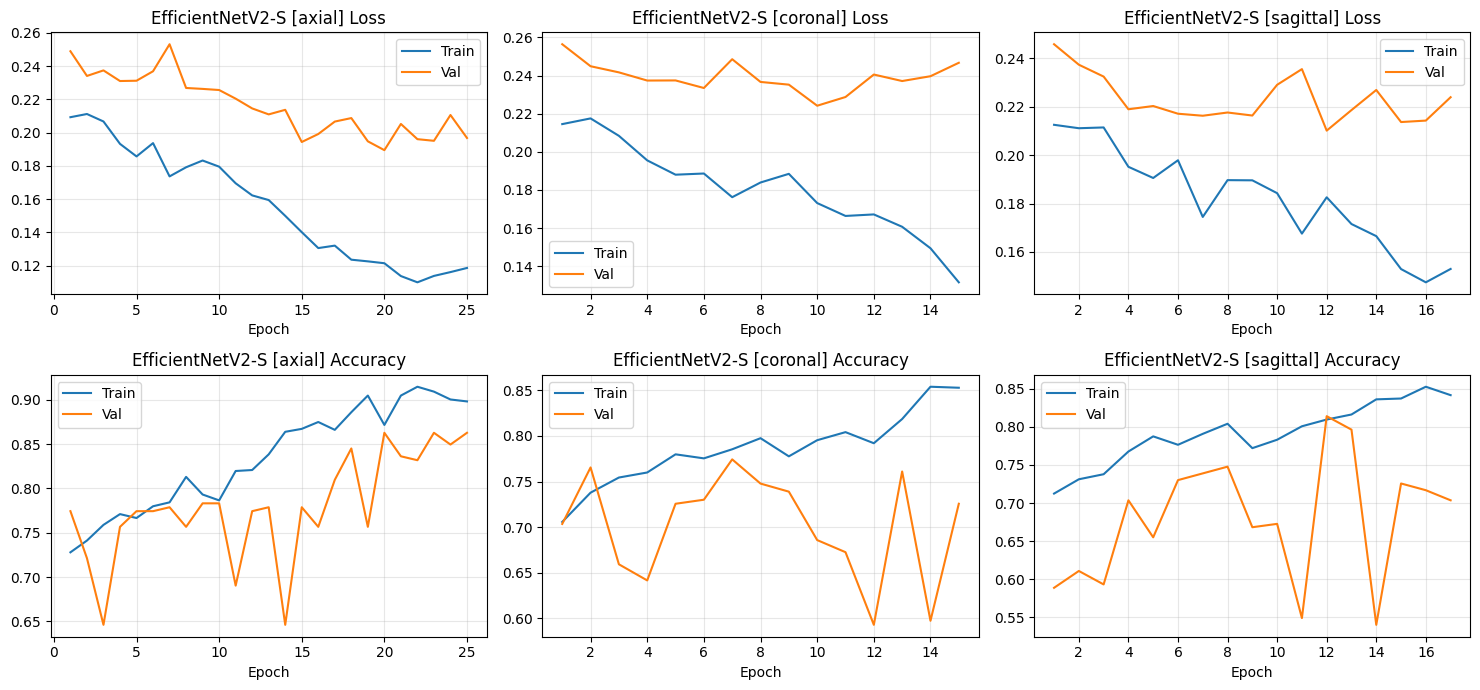

saved /content/drive/MyDrive/ACL_outputs/curves_EfficientNetV2-S.png
  Learned weights: axial=3.590, coronal=1.124, sagittal=0.671
{'Model': 'EfficientNetV2-S', 'Parameters (M)': 20.5068, 'Fusion': 'learned', 'Accuracy': 0.8333, 'Precision': 0.7931, 'Recall': 0.8519, 'Specificity': 0.8182, 'F1-Score': 0.8214, 'AUC': 0.9133, 'Training Time (s)': 5624.6296}
EfficientNetV2-S: threshold=0.170 | fusion=learned | test AUC per view: axial=0.9105, coronal=0.7710, sagittal=0.8519
► Saved to Drive. Completed so far: {'MRNet-AlexNet (Baseline)', 'EfficientNetV2-S', 'ResNet-50'}


In [ ]:
train_model('EfficientNetV2-S')


  ConvNeXt-Tiny

--- View: axial ---
  GPU before build: 448 MB
  ConvNeXt-Tiny|axial: 28.0M params | grad_ckpt=False | GPU after build: 558 MB
  [ConvNeXt-Tiny|axial] ep 01 | tr 0.2666/0.646 | val 0.2483/0.801 auc 0.749 | GPU 886 MB
  [ConvNeXt-Tiny|axial] ep 02 | tr 0.2071/0.711 | val 0.2502/0.239 auc 0.805 | GPU 886 MB
  [ConvNeXt-Tiny|axial] ep 03 | tr 0.2053/0.728 | val 0.2218/0.677 auc 0.817 | GPU 886 MB
  [ConvNeXt-Tiny|axial] ep 04 | tr 0.1913/0.800 | val 0.2316/0.584 auc 0.811 | GPU 886 MB
  [ConvNeXt-Tiny|axial] ep 05 | tr 0.1868/0.779 | val 0.2327/0.783 auc 0.802 | GPU 886 MB
  [ConvNeXt-Tiny|axial] ep 06 | tr 0.1707/0.834 | val 0.2161/0.810 auc 0.821 | GPU 886 MB
  [ConvNeXt-Tiny|axial] ep 07 | tr 0.1582/0.823 | val 0.2119/0.783 auc 0.822 | GPU 886 MB
  [ConvNeXt-Tiny|axial] ep 08 | tr 0.1569/0.852 | val 0.2114/0.774 auc 0.822 | GPU 886 MB
  [ConvNeXt-Tiny|axial] ep 09 | tr 0.1765/0.792 | val 0.4147/0.814 auc 0.841 | GPU 886 MB
  [ConvNeXt-Tiny|axial] ep 10 | tr 0.1917/0.7

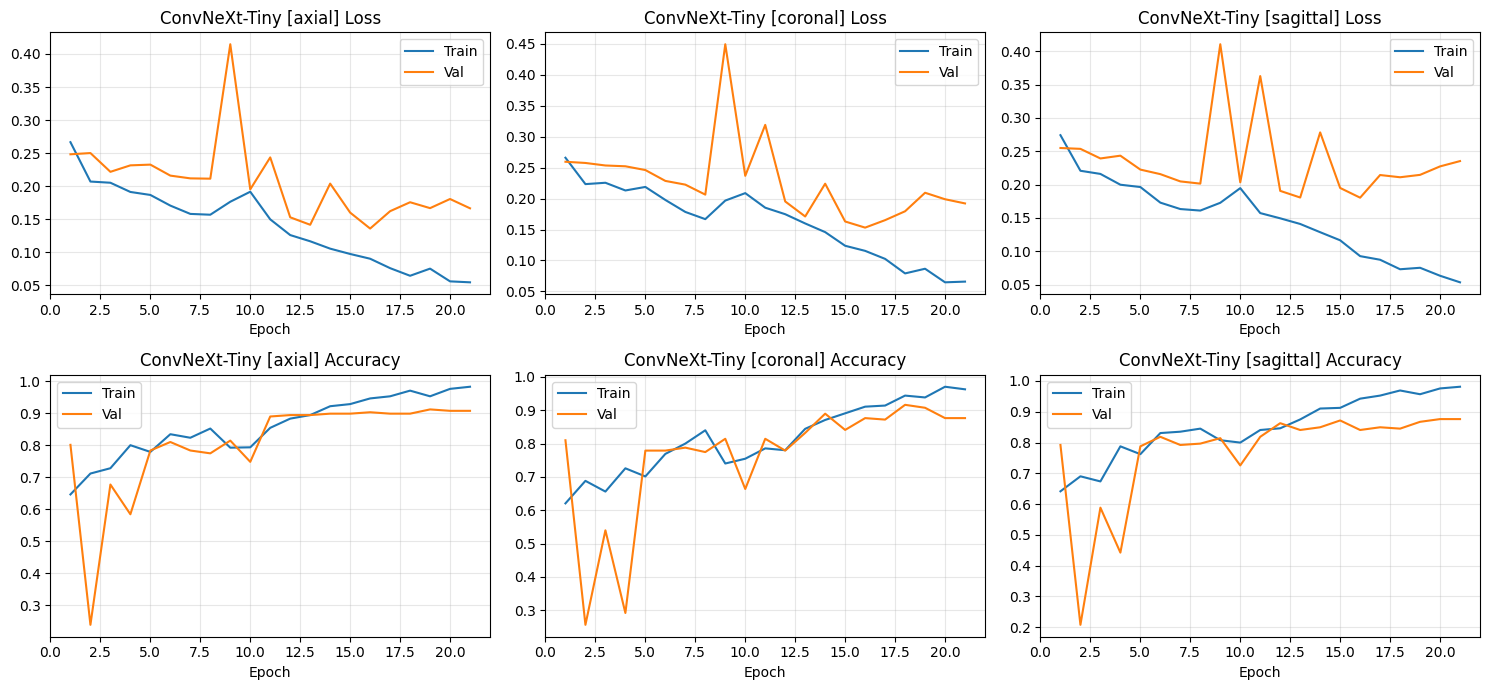

saved /content/drive/MyDrive/ACL_outputs/curves_ConvNeXt-Tiny.png
  Learned weights: axial=2.704, coronal=2.351, sagittal=1.549
{'Model': 'ConvNeXt-Tiny', 'Parameters (M)': 28.0179, 'Fusion': 'learned', 'Accuracy': 0.95, 'Precision': 0.9138, 'Recall': 0.9815, 'Specificity': 0.9242, 'F1-Score': 0.9464, 'AUC': 0.97, 'Training Time (s)': 2498.3828}
ConvNeXt-Tiny: threshold=0.125 | fusion=learned | test AUC per view: axial=0.9700, coronal=0.9672, sagittal=0.9520
► Saved to Drive. Completed so far: {'MRNet-AlexNet (Baseline)', 'ConvNeXt-Tiny', 'EfficientNetV2-S', 'ResNet-50'}


In [ ]:
train_model('ConvNeXt-Tiny')


  Swin-T

--- View: axial ---
  GPU before build: 516 MB
  Swin-T|axial: 27.7M params | grad_ckpt=True | GPU after build: 628 MB
  [Swin-T|axial] ep 01 | tr 0.2165/0.739 | val 0.2511/0.810 auc 0.752 | GPU 953 MB
  [Swin-T|axial] ep 02 | tr 0.2131/0.710 | val 0.2365/0.796 auc 0.784 | GPU 953 MB
  [Swin-T|axial] ep 03 | tr 0.1959/0.753 | val 0.2209/0.774 auc 0.800 | GPU 953 MB
  [Swin-T|axial] ep 04 | tr 0.1853/0.796 | val 0.2461/0.832 auc 0.792 | GPU 953 MB
  [Swin-T|axial] ep 05 | tr 0.1814/0.809 | val 0.2299/0.783 auc 0.804 | GPU 953 MB
  [Swin-T|axial] ep 06 | tr 0.1734/0.810 | val 0.2172/0.748 auc 0.799 | GPU 953 MB
  [Swin-T|axial] ep 07 | tr 0.1575/0.836 | val 0.2202/0.761 auc 0.800 | GPU 953 MB
  [Swin-T|axial] ep 08 | tr 0.1625/0.824 | val 0.2190/0.761 auc 0.801 | GPU 953 MB
  [Swin-T|axial] ep 09 | tr 0.1866/0.803 | val 0.2188/0.761 auc 0.807 | GPU 953 MB
  [Swin-T|axial] ep 10 | tr 0.1662/0.802 | val 0.2347/0.659 auc 0.815 | GPU 953 MB
  [Swin-T|axial] ep 11 | tr 0.1598/0.832

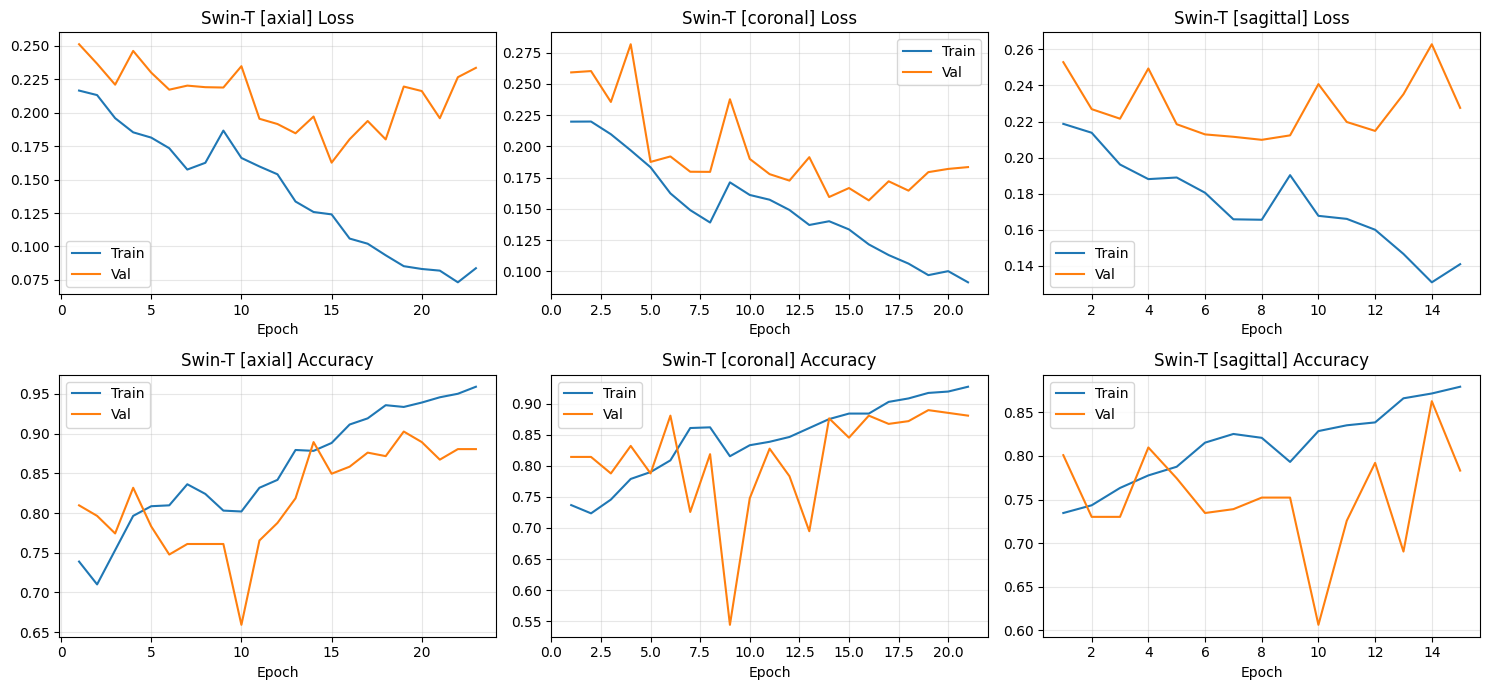

saved /content/drive/MyDrive/ACL_outputs/curves_Swin-T.png
  Learned weights: axial=2.559, coronal=2.917, sagittal=1.133
{'Model': 'Swin-T', 'Parameters (M)': 27.7171, 'Fusion': 'learned', 'Accuracy': 0.925, 'Precision': 0.8947, 'Recall': 0.9444, 'Specificity': 0.9091, 'F1-Score': 0.9189, 'AUC': 0.9641, 'Training Time (s)': 3880.3713}
Swin-T: threshold=0.195 | fusion=learned | test AUC per view: axial=0.9576, coronal=0.9444, sagittal=0.9220
► Saved to Drive. Completed so far: {'ResNet-50', 'Swin-T', 'MRNet-AlexNet (Baseline)', 'EfficientNetV2-S', 'ConvNeXt-Tiny'}


In [ ]:
train_model('Swin-T')

In [ ]:
print(pd.DataFrame(costs).round(1).to_string(index=False))

                   Model  Peak Train Memory (MB)  Training Time (s)
MRNet-AlexNet (Baseline)                   135.8              971.9
               ResNet-50                  1463.1             2610.6
        EfficientNetV2-S                  2447.3             5624.6
           ConvNeXt-Tiny                  2409.0             2498.4
                  Swin-T                  2551.8             3880.4


## Step 10: Confusion Matrices & ROC Curves

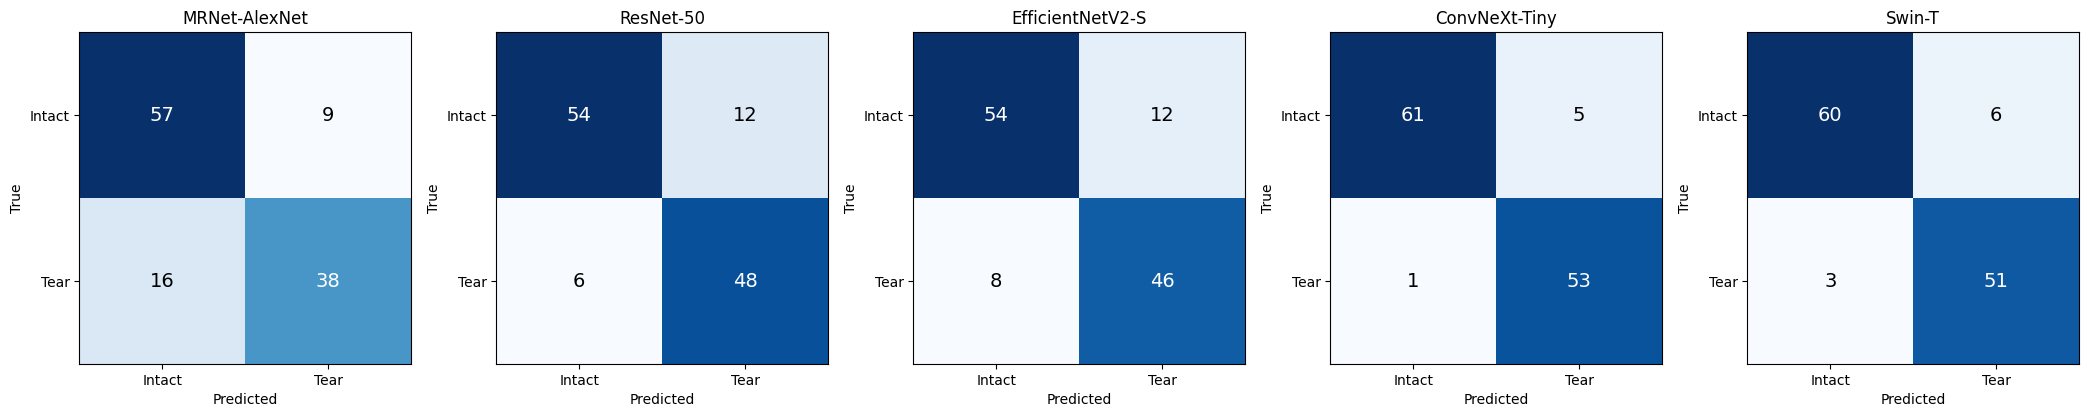

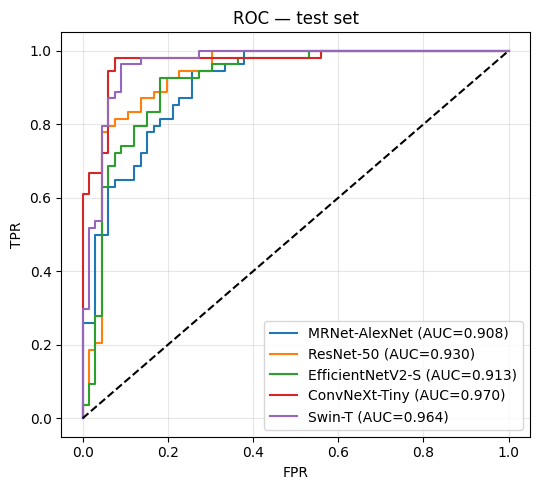

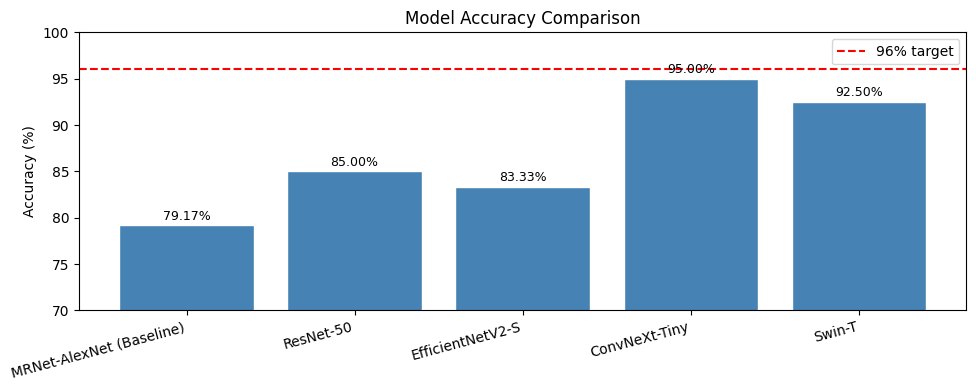

In [ ]:
if len(STORE) == 0:
    print('No models trained yet — run Step 9 first.'); raise SystemExit

# ── Confusion matrices ────────────────────────────────────────────────────────
fig, ax = plt.subplots(1, len(STORE), figsize=(4.2*len(STORE), 4), squeeze=False)
for a, (n, d) in zip(ax[0], STORE.items()):
    cm = confusion_matrix(d['y'], d['pred'], labels=[0,1])
    a.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2):
            a.text(j, i, cm[i,j], ha='center', va='center', fontsize=14,
                   color='white' if cm[i,j] > cm.max()/2 else 'black')
    a.set(title=n.split(' (')[0], xlabel='Predicted', ylabel='True',
          xticks=[0,1], yticks=[0,1],
          xticklabels=['Intact','Tear'], yticklabels=['Intact','Tear'])
plt.tight_layout()
plt.savefig(f"{CFG['out_dir']}/confusion_matrices.png", dpi=100); plt.show()

# ── ROC curves ────────────────────────────────────────────────────────────────
plt.figure(figsize=(5.5,5))
for n, d in STORE.items():
    f_, t_, _ = roc_curve(d['y'], d['s'])
    plt.plot(f_, t_, label=f"{n.split(' (')[0]} (AUC={roc_auc_score(d['y'],d['s']):.3f})")
plt.plot([0,1],[0,1],'k--')
plt.xlabel('FPR'); plt.ylabel('TPR')
plt.title('ROC — test set'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout()
plt.savefig(f"{CFG['out_dir']}/roc_curves.png", dpi=100); plt.show()

# ── Accuracy bar ──────────────────────────────────────────────────────────────
df = pd.DataFrame(results)
fig, ax = plt.subplots(figsize=(max(6, 2*len(df)), 4))
bars = ax.bar(df['Model'], df['Accuracy']*100, color='steelblue', edgecolor='white')
ax.axhline(96, color='red', linestyle='--', linewidth=1.5, label='96% target')
for bar, acc in zip(bars, df['Accuracy']):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
            f'{acc*100:.2f}%', ha='center', va='bottom', fontsize=9)
ax.set(ylabel='Accuracy (%)', title='Model Accuracy Comparison', ylim=(70,100))
ax.set_xticklabels(df['Model'], rotation=15, ha='right')
ax.legend(); plt.tight_layout()
plt.savefig(f"{CFG['out_dir']}/accuracy_comparison.png", dpi=100); plt.show()

## Step 11: Results Summary & CSV Export

In [ ]:
df = pd.DataFrame(results)
df['score'] = (0.6 * df['F1-Score']
             + 0.2 * (1 - df['Training Time (s)']/df['Training Time (s)'].max())
             + 0.2 * (1 - df['Parameters (M)']/df['Parameters (M)'].max()))

best  = df.sort_values(['F1-Score','Accuracy'], ascending=False).iloc[0]
final = df.sort_values('score', ascending=False).iloc[0]
d_idx = df.set_index('Model')

cols = ['Model','Parameters (M)','Accuracy','Precision','Recall',
        'Specificity','F1-Score','AUC','Training Time (s)']

analysis_lines = [
    f"1. Highest accuracy:   {d_idx['Accuracy'].idxmax()} ({d_idx['Accuracy'].max()*100:.2f}%)",
    f"2. Highest F1-score:   {d_idx['F1-Score'].idxmax()} ({d_idx['F1-Score'].max():.4f})",
    f"3. Highest AUC:        {d_idx['AUC'].idxmax()} ({d_idx['AUC'].max():.4f})",
    f"4. Most suitable:      {final.Model} (60% F1 + 20% speed + 20% size)",
    f"5. Target 96% accuracy: {'ACHIEVED ✓' if d_idx['Accuracy'].max()>=0.96 else 'NOT YET — use full dataset + 25 epochs'}"
]

print('\n'.join(analysis_lines))
print('\nFull results:')
print(df[cols].round(4).to_string(index=False))

df[cols].round(4).to_csv(f"{CFG['out_dir']}/comparative_metrics.csv", index=False)
print(f"\nSaved to {CFG['out_dir']}/comparative_metrics.csv")

with open(f"{CFG['out_dir']}/results_summary.txt", 'w') as f:
    f.write(f"Paper: {PAPER['title']}\nJournal: {PAPER['journal']}\n")
    f.write('\n## Analysis\n' + '\n'.join(analysis_lines))
    f.write('\n\n## Notes\n' + '\n'.join(extra))

1. Highest accuracy:   ConvNeXt-Tiny (95.00%)
2. Highest F1-score:   ConvNeXt-Tiny (0.9464)
3. Highest AUC:        ConvNeXt-Tiny (0.9700)
4. Most suitable:      MRNet-AlexNet (Baseline) (60% F1 + 20% speed + 20% size)
5. Target 96% accuracy: NOT YET — use full dataset + 25 epochs

Full results:
                   Model  Parameters (M)  Accuracy  Precision  Recall  Specificity  F1-Score    AUC  Training Time (s)
MRNet-AlexNet (Baseline)          2.5359    0.7917     0.8085  0.7037       0.8636    0.7525 0.9077           971.8991
               ResNet-50         24.0348    0.8500     0.8000  0.8889       0.8182    0.8421 0.9301          2610.5867
        EfficientNetV2-S         20.5068    0.8333     0.7931  0.8519       0.8182    0.8214 0.9133          5624.6296
           ConvNeXt-Tiny         28.0179    0.9500     0.9138  0.9815       0.9242    0.9464 0.9700          2498.3828
                  Swin-T         27.7171    0.9250     0.8947  0.9444       0.9091    0.9189 0.9641          

## Step 12: Application Demo — Best Model

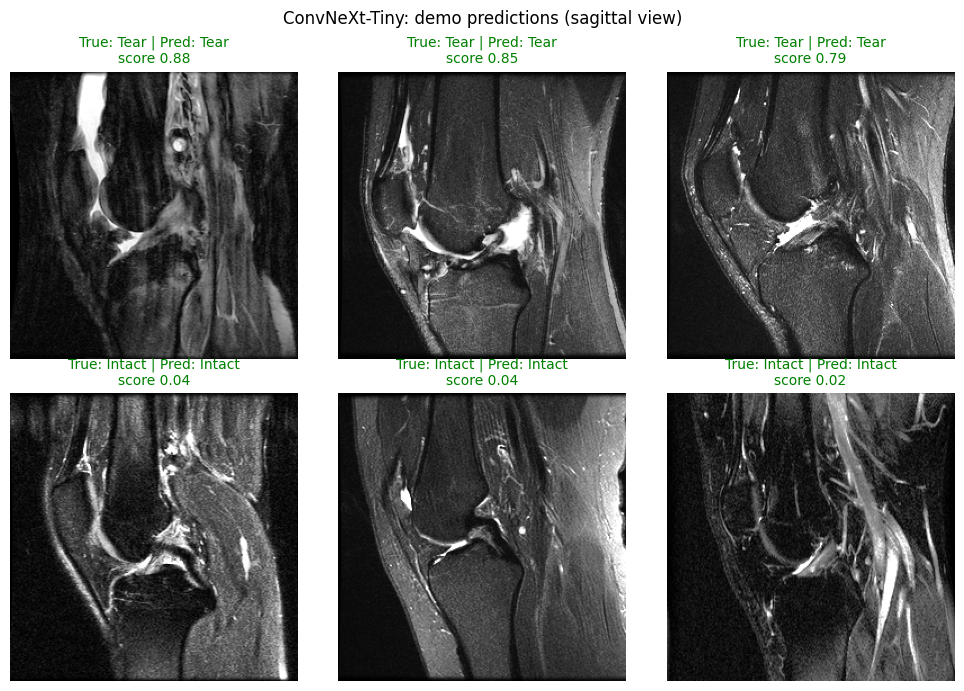

In [ ]:
fm = df.sort_values('F1-Score', ascending=False).iloc[0]['Model']
Sx = STORE[fm]
v0 = 'sagittal' if 'sagittal' in VIEWS else VIEWS[0]
rng = np.random.default_rng(0)
idx = np.concatenate([
    rng.choice(np.where(Sx['y']==c)[0], min(3, int((Sx['y']==c).sum())), replace=False)
    for c in [1,0]
])

fig, ax = plt.subplots(2, 3, figsize=(10, 7))
for a, i in zip(ax.flat, idx):
    ok = bool(Sx['pred'][i]) == bool(Sx['y'][i])
    a.imshow(DATA[v0]['test'][0][i][K//2], cmap='gray'); a.axis('off')
    a.set_title(
        f"True: {'Tear' if Sx['y'][i] else 'Intact'} | "
        f"Pred: {'Tear' if Sx['pred'][i] else 'Intact'}\n"
        f"score {Sx['s'][i]:.2f}",
        color='green' if ok else 'red', fontsize=10
    )
plt.suptitle(f'{fm}: demo predictions ({v0} view)')
plt.tight_layout()
plt.savefig(f"{CFG['out_dir']}/demo_predictions.png", dpi=100); plt.show()

## Step 13: Grad-CAM — Memory-Safe (top-2 models only, weights from disk)


GradCAM for: ['ConvNeXt-Tiny', 'Swin-T']


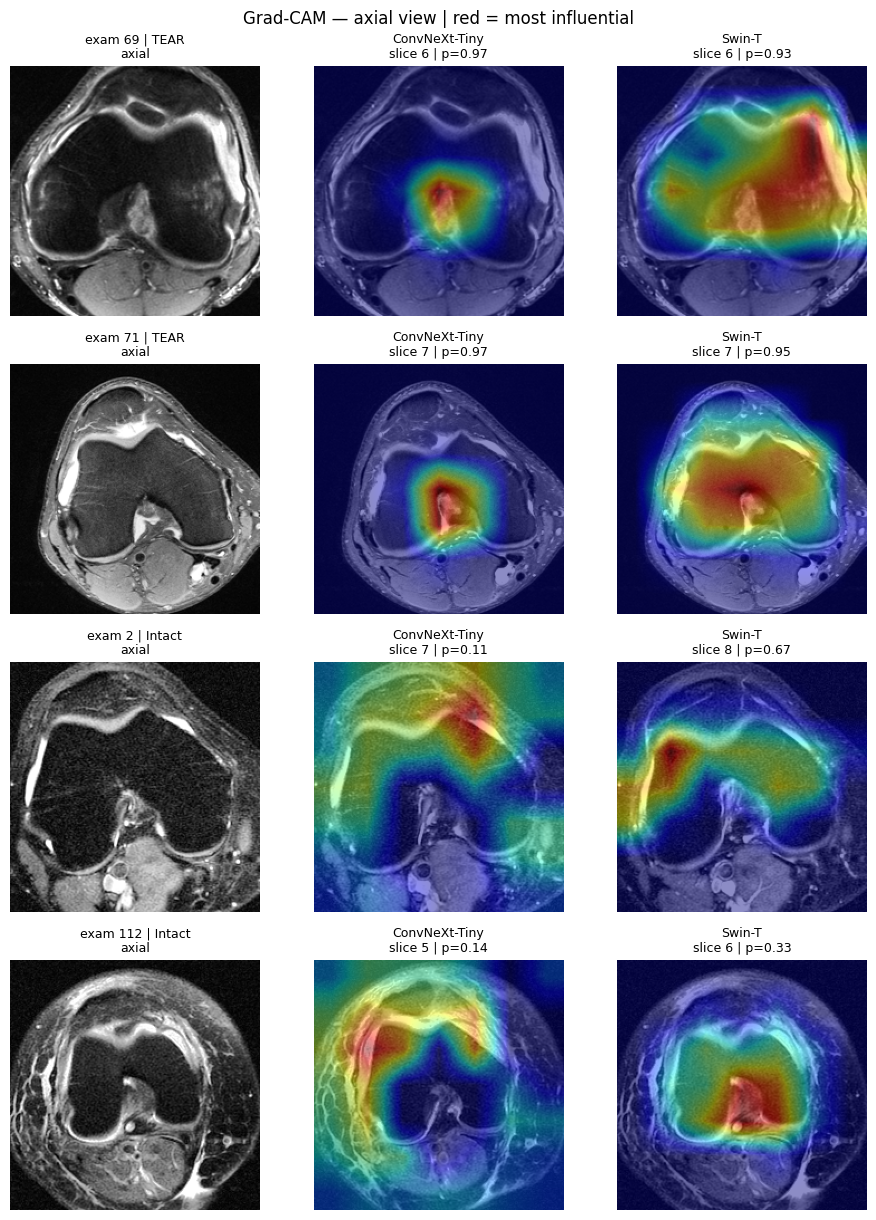

saved /content/drive/MyDrive/ACL_outputs/gradcam_axial.png


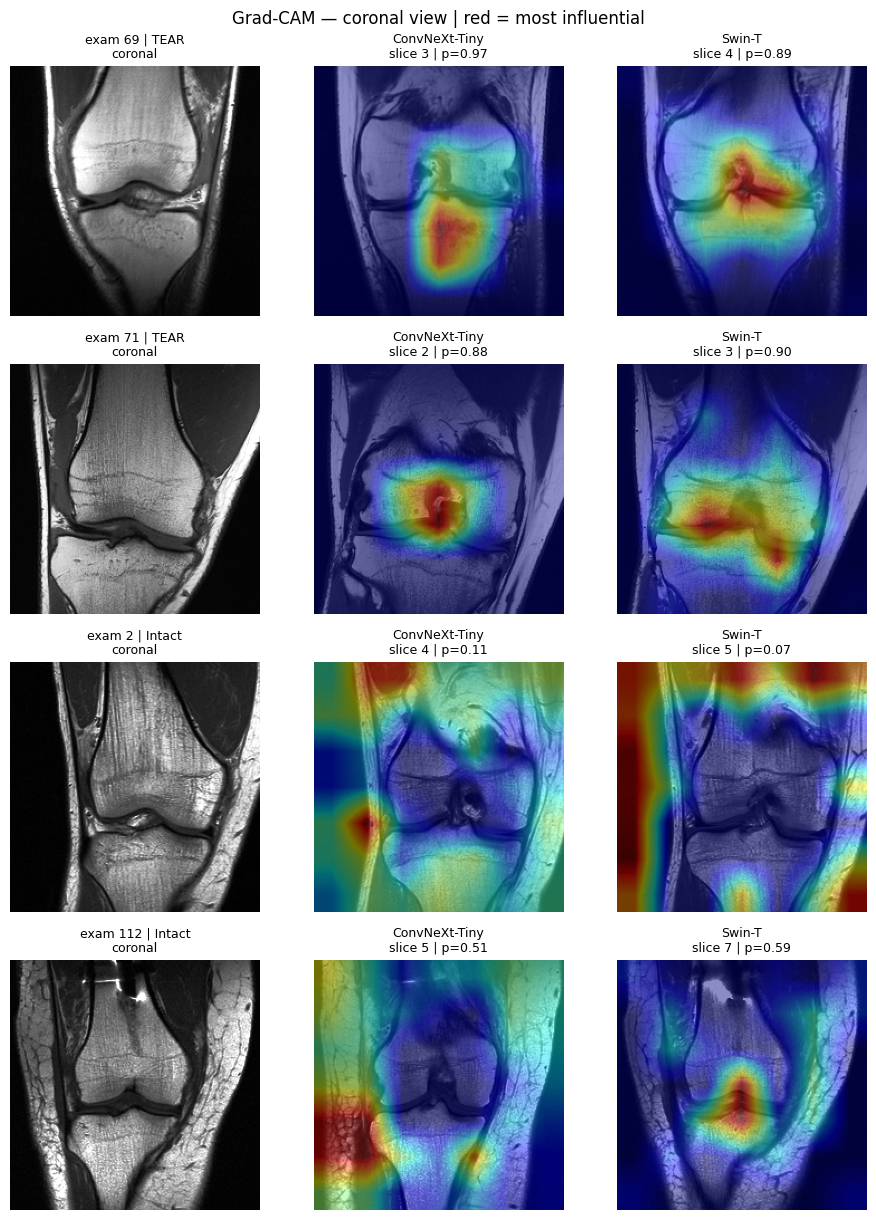

saved /content/drive/MyDrive/ACL_outputs/gradcam_coronal.png


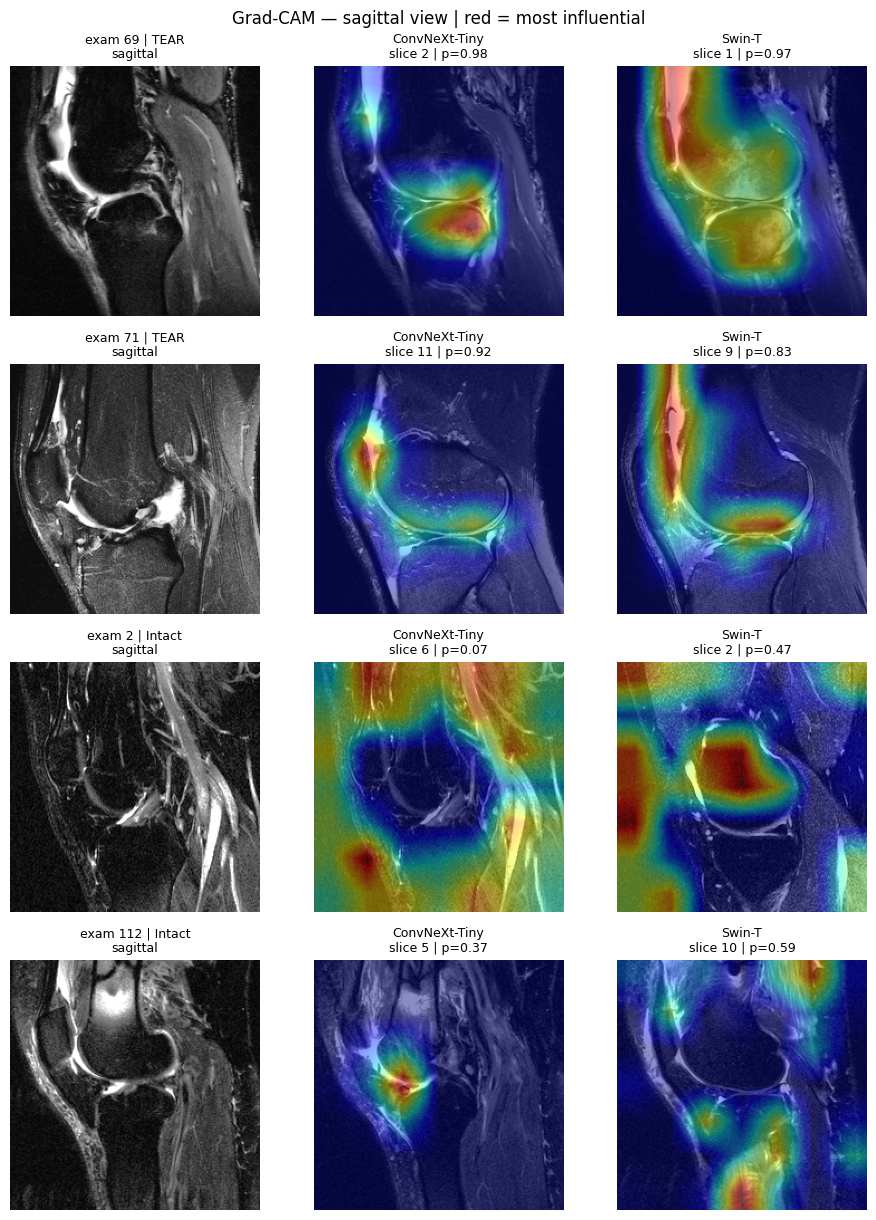

saved /content/drive/MyDrive/ACL_outputs/gradcam_sagittal.png
Final outputs: ['accuracy_comparison.png', 'ckpt', 'class_distribution.png', 'comparative_metrics.csv', 'confusion_matrices.png', 'curves_ConvNeXt-Tiny.png', 'curves_EfficientNetV2-S.png', 'curves_MRNet-AlexNet.png', 'curves_ResNet-50.png', 'curves_Swin-T.png', 'demo_predictions.png', 'gradcam_axial.png', 'gradcam_coronal.png', 'gradcam_sagittal.png', 'partial_results.pkl', 'results_summary.txt', 'roc_curves.png', 'sample_images.png', 'summary_ConvNeXt_Tiny.json', 'summary_EfficientNetV2_S.json', 'summary_Swin_T.json']


In [ ]:
import matplotlib.cm as mpl_cm

def gc_target(name, bb):
    if name.startswith('MRNet-AlexNet'): return bb[0][11]
    if name.startswith('ResNet'):        return bb.layer4[-1]
    if 'EfficientNet' in name:           return bb.bn2
    if 'ConvNeXt' in name:               return bb.stages[-1]
    if 'Swin' in name:                   return bb.layers[-1]
    raise ValueError(name)


def load_from_disk(name, view):
    """Load model from disk checkpoint — no STATES dict needed."""
    p = CFG['pretrained']; CFG['pretrained'] = False
    try:
        bb, d = BUILDERS[name]()
    finally:
        CFG['pretrained'] = p
    m = GatedAttentionMIL(bb, d)
    cp = ckpt_path(name, view)
    if os.path.exists(cp):
        m.load_state_dict(torch.load(cp, map_location='cpu'))
    else:
        print(f'Warning: no checkpoint at {cp}')
    return m.to(DEV).eval(), d


def grad_cam(model, layer, x, d):
    store = {}
    def fh(m, inp, out):
        store['a'] = out
        out.register_hook(lambda g: store.__setitem__('g', g))
    h = layer.register_forward_hook(fh)
    try:
        with torch.enable_grad():
            feats  = model.backbone(x.unsqueeze(0).flatten(0,1).to(DEV))
            feats_v = feats.view(1, x.shape[0], -1)
            a_sc   = torch.softmax(
                model.attn_w(model.attn_V(feats_v) * model.attn_U(feats_v)), dim=1
            ).squeeze()
            logit  = model.head((a_sc.unsqueeze(-1)*feats_v).sum(1)).squeeze()
            model.zero_grad(set_to_none=True); logit.backward()
    finally:
        h.remove()
    a, g = store['a'].detach(), store['g'].detach()
    if a.shape[1] != d and a.shape[-1] == d:
        a, g = a.permute(0,3,1,2), g.permute(0,3,1,2)
    cam = F.relu((g.mean((2,3), keepdim=True)*a).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[:,0]
    cam = cam / (cam.amax((1,2), keepdim=True) + 1e-8)
    best_s = int(a_sc.argmax().cpu())
    return cam.cpu().numpy(), best_s, float(torch.sigmoid(logit).item())


def overlay(img, cam, alpha=.45):
    img = (img - img.min()) / (img.max()-img.min()+1e-8)
    return np.clip((1-alpha)*np.stack([img]*3, -1) + alpha*mpl_cm.jet(cam)[...,:3], 0, 1)


# ── Only run GradCAM for the top-2 models by F1 to save time ────────────────
top2_names = df.sort_values('F1-Score', ascending=False).head(2)['Model'].tolist()
print('GradCAM for:', top2_names)

yte = STORE[list(STORE.keys())[0]]['y']
rg  = np.random.default_rng(1)
GC_IDX = np.concatenate([rg.choice(np.where(yte==c)[0], 2, replace=False) for c in [1,0]])

for view in VIEWS:
    ds  = KneeMRI('test', view, False)
    n_models_for_cam = len(top2_names)
    fig, ax = plt.subplots(len(GC_IDX), 1+n_models_for_cam,
                           figsize=(3.1*(1+n_models_for_cam), 3.1*len(GC_IDX)), squeeze=False)
    for j, name in enumerate(top2_names):
        try:
            model, d = load_from_disk(name, view)
            layer    = gc_target(name, model.backbone)
            for r, i in enumerate(GC_IDX):
                x, _ = ds[i]
                cam, best_s, p_tear = grad_cam(model, layer, x, d)
                if j == 0:
                    ax[r,0].imshow(x[K//2,0], cmap='gray'); ax[r,0].axis('off')
                    ax[r,0].set_title(f'exam {i} | {"TEAR" if yte[i] else "Intact"}\n{view}', fontsize=9)
                ax[r,1+j].imshow(overlay(x[best_s,0].numpy(), cam[best_s]))
                ax[r,1+j].axis('off')
                ax[r,1+j].set_title(f'{name.split(" (")[0]}\nslice {best_s} | p={p_tear:.2f}', fontsize=9)
            model.cpu(); del model
            free_gpu()
        except Exception as e:
            print(f'GradCAM skipped {name}/{view}: {e}')
    plt.suptitle(f'Grad-CAM — {view} view | red = most influential')
    plt.tight_layout()
    fn = f"{CFG['out_dir']}/gradcam_{view}.png"
    plt.savefig(fn, dpi=100, bbox_inches='tight'); plt.show(); print('saved', fn)

print('Final outputs:', sorted(os.listdir(CFG['out_dir'])))

In [ ]:
%run -i "/content/drive/MyDrive/export_for_app.py"


── MRNet-AlexNet (Baseline)
  thr=0.146  acc=0.8000  auc=0.8965

── ResNet-50
  thr=0.139  acc=0.8500  auc=0.9259

── EfficientNetV2-S
  thr=0.158  acc=0.8750  auc=0.9175

── ConvNeXt-Tiny
  thr=0.143  acc=0.9500  auc=0.9694

── Swin-T
  thr=0.183  acc=0.9250  auc=0.9672

✓ Wrote /content/deploy.zip (1122 MB)
  Library versions to install on your laptop: {'torch': '2.14.1+cu130', 'torchvision': '0.29.1+cu130', 'timm': '1.0.31', 'sklearn': '1.6.1'}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 640x480 with 0 Axes>

In [ ]:
!cp /content/deploy.zip /content/drive/MyDrive/ACL_outputs/